# Anomaly Detection in Monclova MDA Prices

This notebook implements, evaluates, and visualizes **Anomaly Detection** for hourly Local Marginal Prices (PML) across all 9 Monclova load-zone nodes from January 1, 2024 to June 30, 2025.

### Complementary Dual-Method Design
In wholesale electricity markets, anomalous events emerge from two distinct physical and statistical phenomena:
1. **Method 1: Contextual / Temporal Anomalies (XGBoost Residuals):**
   - Identifies prices that severely deviate from diurnal, weekly, and seasonal market clearing expectations given the specific time context
   - Computed as $|PML_t - \hat{PML}_t| > \tau_{res}$, calibrated at the nominal 98.5th percentile threshold ($\alpha = 1.5\%$).
2. **Method 2: Structural / Physical Component Anomalies (Multivariate Isolation Forest):**
   - An unsupervised tree ensemble isolating observations with abnormal coordinate distances in physical decomposition space ($PML = PML_{ene} + PML_{per} + PML_{cng}$).
   - Captures localized transmission congestion crises ($PML_{cng} \neq 0$) and extreme marginal loss penalties without relying on temporal assumptions ($\alpha = 1.5\%$).
3. **Consensus High-Confidence Alerts:**
   - Hours flagged simultaneously by both methods represent critical grid emergency events suitable for automated dispatch and trading alerts.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest

from src.models.xgboost import (
    FEATURE_COLS,
    build_xgboost_features,
    train_global_xgboost,
    predict_global_xgboost,
)

## Data Ingestion & Model Setup
We load the validated interim dataset (`data/interim/pml_mda.parquet`), construct the leak-free feature matrix, and train the Global XGBoost benchmark on 2024 to generate the expected baseline price series.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "pml_mda.parquet"
raw_df = pd.read_parquet(DATA_PATH)
all_nodes = sorted(raw_df["clv_nodo"].unique())
print(f"Loaded dataset: {len(raw_df):,} records across {len(all_nodes)} Monclova nodes.")

# Build feature matrix
df_feat = build_xgboost_features(raw_df)

# Train Global XGBoost baseline on 2024 horizon (77,544 rows after warmup)
train_mask = (df_feat["timestamp"] >= "2024-01-08") & (df_feat["timestamp"] <= "2024-12-31 23:00:00")
train_df = df_feat[train_mask].copy().reset_index(drop=True)

print("Training Global XGBoost regressor for residual baseline...")
xgb_model = train_global_xgboost(
    train_df=train_df,
    feature_cols=FEATURE_COLS,
    target_col="pml",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

# Evaluate predictions across full valid horizon (Jan 8, 2024 to Jun 30, 2025)
eval_mask = df_feat["timestamp"] >= "2024-01-08"
eval_df = df_feat[eval_mask].copy().reset_index(drop=True)
eval_df["pml_pred_xgb"] = predict_global_xgboost(xgb_model, eval_df, feature_cols=FEATURE_COLS).values

print(f"Generated predictions for {len(eval_df):,} evaluation records.")

Loaded dataset: 118,152 records across 9 Monclova nodes.
Training Global XGBoost regressor for residual baseline...
Generated predictions for 116,640 evaluation records.


## Method 1: Contextual Temporal Anomaly Detection (XGBoost Residuals)
We define temporal prediction residuals as $e_t = |PML_t - \hat{PML}_t|$. Hours where the observed market price drastically decouples from expected diurnal clearing levels are flagged based on the 98.5th percentile threshold ($\alpha = 1.5\%$).

In [3]:
# Compute absolute prediction residuals
eval_df["residual"] = (eval_df["pml"] - eval_df["pml_pred_xgb"]).abs()

# Calibrate anomaly threshold at the 98.5th percentile (1.5% nominal contamination)
res_threshold = eval_df["residual"].quantile(0.985)
eval_df["anom_residual"] = eval_df["residual"] > res_threshold

n_res_anom = eval_df["anom_residual"].sum()
pct_res_anom = eval_df["anom_residual"].mean() * 100

print(f"=== Method 1: XGBoost Residual Anomaly Detection ===")
print(f"Residual Anomaly Threshold (P98.5): ${res_threshold:.2f} MXN/MWh")
print(f"Total Anomalous Hours Flagged: {n_res_anom:,} ({pct_res_anom:.2f}% of total)")
print(f"Mean PML in Normal Hours:    ${eval_df.loc[~eval_df['anom_residual'], 'pml'].mean():.2f}/MWh")
print(f"Mean PML in Anomalous Hours: ${eval_df.loc[eval_df['anom_residual'], 'pml'].mean():.2f}/MWh")

=== Method 1: XGBoost Residual Anomaly Detection ===
Residual Anomaly Threshold (P98.5): $1474.61 MXN/MWh
Total Anomalous Hours Flagged: 1,750 (1.50% of total)
Mean PML in Normal Hours:    $703.56/MWh
Mean PML in Anomalous Hours: $6446.05/MWh


## Method 2: Structural Physical Component Anomaly Detection (Isolation Forest)
We isolate physical component anomalies by fitting an unsupervised `IsolationForest` across the complete CENACE price decomposition vector: $[PML, PML_{ene}, PML_{per}, PML_{cng}]$, calibrated at an expected contamination rate of $\alpha = 1.5\%$.

In [4]:
# Physical decomposition features
physical_features = ["pml", "pml_ene", "pml_per", "pml_cng"]

iso_forest = IsolationForest(
    contamination=0.015,
    random_state=42,
    n_estimators=100,
    n_jobs=-1,
)

eval_df["anom_iso"] = iso_forest.fit_predict(eval_df[physical_features]) == -1

n_iso_anom = eval_df["anom_iso"].sum()
pct_iso_anom = eval_df["anom_iso"].mean() * 100

print(f"=== Method 2: Multivariate Isolation Forest ===")
print(f"Contamination Parameter: 1.50%")
print(f"Total Anomalous Hours Flagged: {n_iso_anom:,} ({pct_iso_anom:.2f}% of total)")
print(f"Mean PML in Normal Hours:    ${eval_df.loc[~eval_df['anom_iso'], 'pml'].mean():.2f}/MWh")
print(f"Mean PML in Anomalous Hours: ${eval_df.loc[eval_df['anom_iso'], 'pml'].mean():.2f}/MWh")
print(f"Max Absolute Congestion in Anomalies: ${eval_df.loc[eval_df['anom_iso'], 'pml_cng'].abs().max():.2f}/MWh")

=== Method 2: Multivariate Isolation Forest ===
Contamination Parameter: 1.50%
Total Anomalous Hours Flagged: 1,749 (1.50% of total)
Mean PML in Normal Hours:    $693.46/MWh
Mean PML in Anomalous Hours: $7112.67/MWh
Max Absolute Congestion in Anomalies: $3717.14/MWh


## Consensus Analysis & Quantitative Evaluation
We evaluate the inter-method consistency between both paradigms (Jaccard similarity coefficient), identify the **Consensus Alerts** (hours where both detectors agree), and verify ground-truth recall on empirical tail-risk shocks (the 99.66th empirical percentile / top 0.34% of market prices).

In [5]:
# Inter-method agreement and consensus
eval_df["anom_consensus"] = eval_df["anom_residual"] & eval_df["anom_iso"]
eval_df["anom_union"] = eval_df["anom_residual"] | eval_df["anom_iso"]

overlap_count = eval_df["anom_consensus"].sum()
union_count = eval_df["anom_union"].sum()
jaccard_similarity = overlap_count / union_count

print(f"=== Quantitative Evaluation & Consensus Agreement ===")
print(f"XGBoost Residuals Only Flagged:     {(eval_df['anom_residual'] & ~eval_df['anom_iso']).sum():,} hours")
print(f"Isolation Forest Only Flagged:      {(eval_df['anom_iso'] & ~eval_df['anom_residual']).sum():,} hours")
print(f"Consensus High-Confidence Alerts:   {overlap_count:,} hours")
print(f"Inter-Method Jaccard Similarity:    {jaccard_similarity:.3f}")

# Ground-truth extreme shock recall (P99.66 empirical tail-risk: top 0.34% of hours)
extreme_spikes = eval_df["pml"] > 10000
recall_extreme_res = eval_df.loc[extreme_spikes, "anom_residual"].mean() * 100
recall_extreme_iso = eval_df.loc[extreme_spikes, "anom_iso"].mean() * 100
recall_extreme_cons = eval_df.loc[extreme_spikes, "anom_consensus"].mean() * 100

print(f"\n--- Ground-Truth Recall on Empirical Tail-Risk Shocks (PML > $10,000/MWh [P99.66]: {extreme_spikes.sum()} hours) ---")
print(f"Method 1 (XGBoost Residuals) Recall:  {recall_extreme_res:.1f}%")
print(f"Method 2 (Isolation Forest) Recall:   {recall_extreme_iso:.1f}%")
print(f"Consensus Detector Recall:           {recall_extreme_cons:.1f}%")

# Node-by-node anomaly breakdown with compact headers to prevent PDF clipping
node_anom_records = []
for node in all_nodes:
    node_df = eval_df[eval_df["clv_nodo"] == node]
    node_anom_records.append({
        "Node": node,
        "Hours": len(node_df),
        "Res_Anom": int(node_df["anom_residual"].sum()),
        "Iso_Anom": int(node_df["anom_iso"].sum()),
        "Consensus": int(node_df["anom_consensus"].sum()),
        "Cons_Rate": f"{node_df['anom_consensus'].mean()*100:.2f}%",
    })

node_anom_table = pd.DataFrame(node_anom_records)
print(f"\n=== Anomaly Breakdown Across All 9 Monclova Nodes ===")
display(node_anom_table)

=== Quantitative Evaluation & Consensus Agreement ===
XGBoost Residuals Only Flagged:     713 hours
Isolation Forest Only Flagged:      712 hours
Consensus High-Confidence Alerts:   1,037 hours
Inter-Method Jaccard Similarity:    0.421

--- Ground-Truth Recall on Empirical Tail-Risk Shocks (PML > $10,000/MWh [P99.66]: 402 hours) ---
Method 1 (XGBoost Residuals) Recall:  92.0%
Method 2 (Isolation Forest) Recall:   100.0%
Consensus Detector Recall:           92.0%

=== Anomaly Breakdown Across All 9 Monclova Nodes ===


,Node,Hours,Res_Anom,Iso_Anom,Consensus,Cons_Rate
0,06AEO-115,12960,196,192,116,0.90%
1,06AHM-400,12960,194,199,116,0.90%
2,06FRO-115,12960,194,196,115,0.89%
3,06GRA-115,12960,195,192,115,0.89%
4,06MON-115,12960,193,195,115,0.89%
5,06MON-230,12960,193,195,115,0.89%
6,06RGS-115,12960,195,193,115,0.89%
7,06TKS-115,12960,194,196,115,0.89%
8,06XOC-115,12960,196,191,115,0.89%


## Anomaly Visualizations
We visualize detected anomalies on the central reference node `06MON-115` across three operational perspectives:
1. **Macro View (Full 18-Month Timeline):** System-wide distribution of consensus alerts across the full horizon.
2. **Operational Role Decomposition (May 20–26, 2024):** 2-panel comparative diagnosis contrasting **Trader / Market Profile (XGBoost Residuals)** in blue vs. **Grid / Transmission Engineering Profile (Isolation Forest)** in orange.
3. **Executive Consensus Zoom (May 20–26, 2024):** High-confidence emergency alerts for Executive Risk Management in red, annotating the historic record shock.

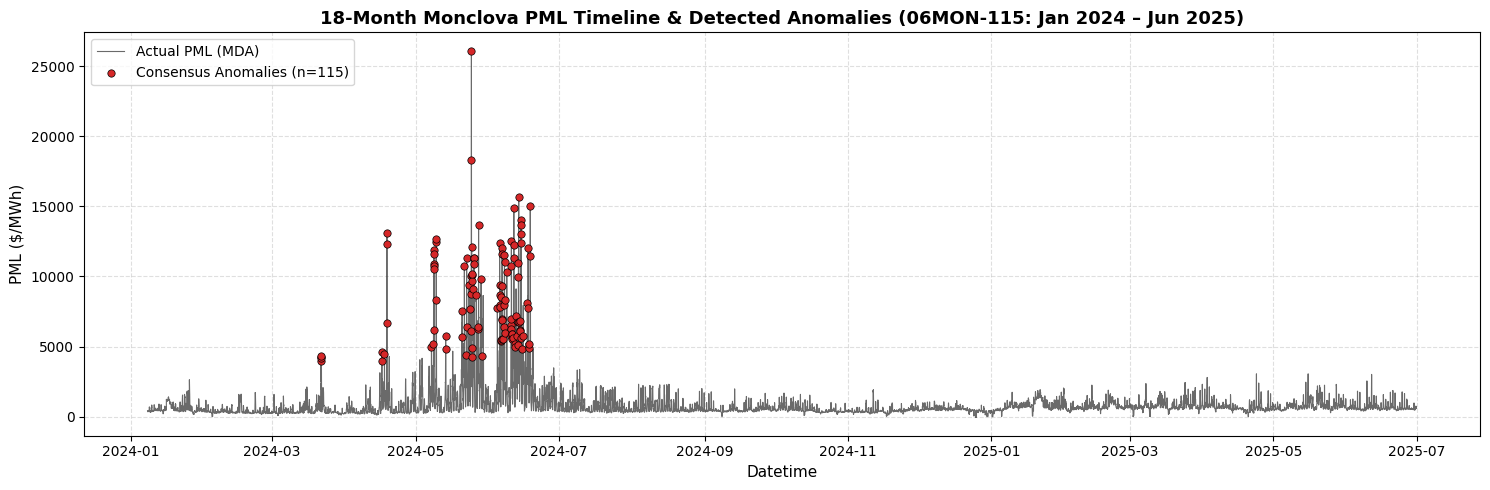

In [6]:
REF_NODE = "06MON-115"
ref_eval = eval_df[eval_df["clv_nodo"] == REF_NODE].set_index("timestamp").sort_index()

plt.figure(figsize=(15, 5))
plt.plot(ref_eval.index, ref_eval["pml"], color="#2b2b2b", linewidth=0.8, alpha=0.7, label="Actual PML (MDA)")

# Scatter consensus anomalies in bright red
consensus_points = ref_eval[ref_eval["anom_consensus"]]
plt.scatter(
    consensus_points.index,
    consensus_points["pml"],
    color="#d62728",
    s=28,
    zorder=5,
    label=f"Consensus Anomalies (n={len(consensus_points)})",
    edgecolor="black",
    linewidth=0.5,
)

plt.title(f"18-Month Monclova PML Timeline & Detected Anomalies ({REF_NODE}: Jan 2024 – Jun 2025)", fontsize=13, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper left", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

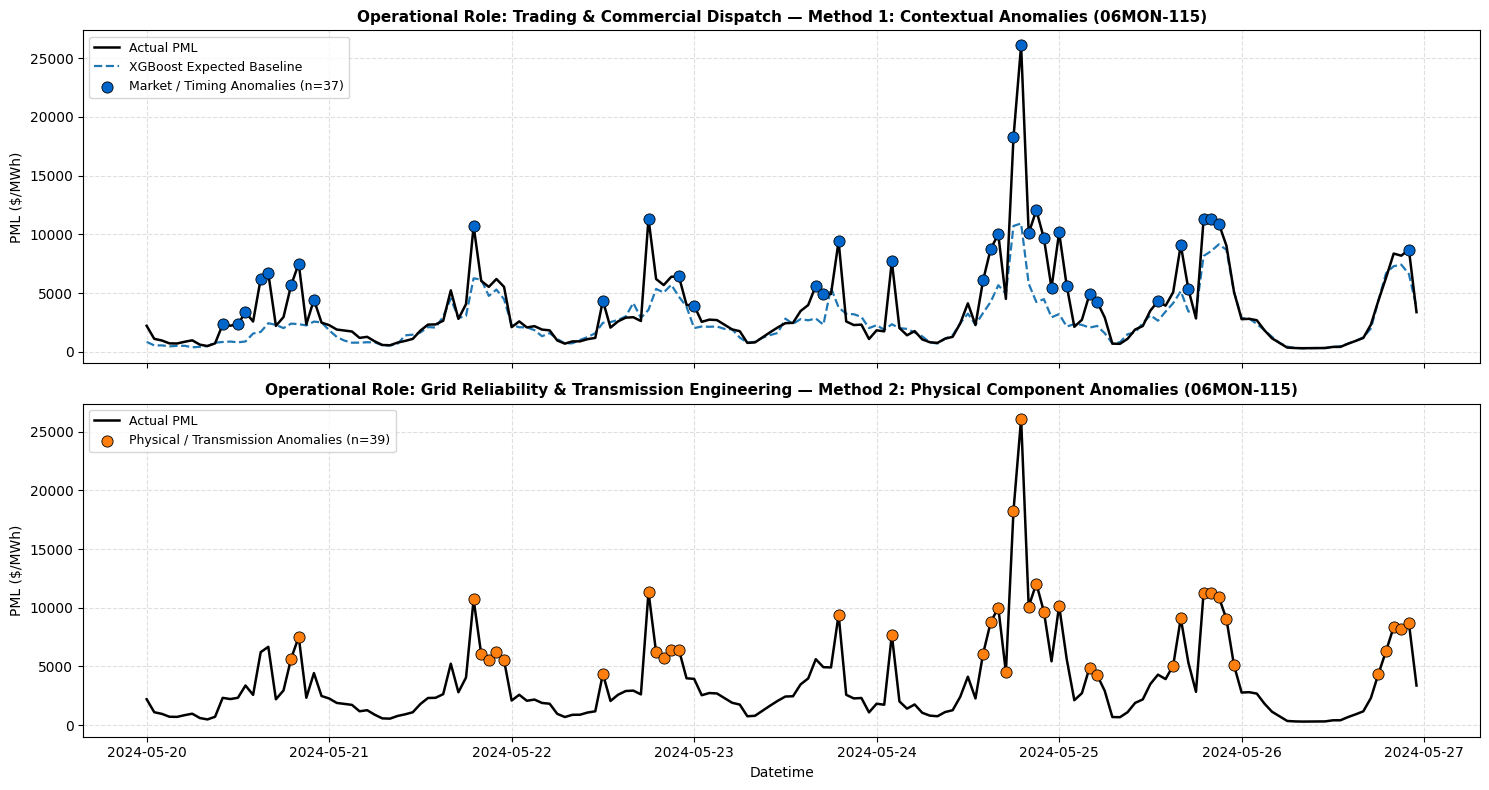

Role 1 (Market/XGBoost) Flagged: 37 hrs | Role 2 (Grid/IsoForest) Flagged: 39 hrs out of 168 hrs.


In [7]:
# Acute Price Spike Crisis Week: May 20 - May 26, 2024
crisis_mask = (ref_eval.index >= "2024-05-20") & (ref_eval.index <= "2024-05-26 23:00:00")
crisis_df = ref_eval.loc[crisis_mask]

# 2-Panel Role-Based Decomposition
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

# Panel 1: Trading & Commercial Dispatch Profile (XGBoost Residuals)
ax1.plot(crisis_df.index, crisis_df["pml"], color="black", linewidth=1.8, label="Actual PML", zorder=2)
ax1.plot(crisis_df.index, crisis_df["pml_pred_xgb"], color="#1f77b4", linestyle="--", linewidth=1.6, label="XGBoost Expected Baseline", zorder=1)
xgb_anom = crisis_df[crisis_df["anom_residual"]]
ax1.scatter(
    xgb_anom.index,
    xgb_anom["pml"],
    color="#0066cc",
    s=65,
    zorder=4,
    label=f"Market / Timing Anomalies (n={len(xgb_anom)})",
    edgecolor="black",
    linewidth=0.6,
)
ax1.set_title(f"Operational Role: Trading & Commercial Dispatch — Method 1: Contextual Anomalies ({REF_NODE})", fontsize=11, fontweight="bold")
ax1.set_ylabel("PML ($/MWh)", fontsize=10)
ax1.legend(loc="upper left", frameon=True, fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.4)

# Panel 2: Grid Reliability & Substation Engineering Profile (Isolation Forest)
ax2.plot(crisis_df.index, crisis_df["pml"], color="black", linewidth=1.8, label="Actual PML", zorder=2)
iso_anom = crisis_df[crisis_df["anom_iso"]]
ax2.scatter(
    iso_anom.index,
    iso_anom["pml"],
    color="#ff7f0e",
    s=65,
    zorder=4,
    label=f"Physical / Transmission Anomalies (n={len(iso_anom)})",
    edgecolor="black",
    linewidth=0.6,
)
ax2.set_title(f"Operational Role: Grid Reliability & Transmission Engineering — Method 2: Physical Component Anomalies ({REF_NODE})", fontsize=11, fontweight="bold")
ax2.set_xlabel("Datetime", fontsize=10)
ax2.set_ylabel("PML ($/MWh)", fontsize=10)
ax2.legend(loc="upper left", frameon=True, fontsize=9)
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Role 1 (Market/XGBoost) Flagged: {len(xgb_anom)} hrs | Role 2 (Grid/IsoForest) Flagged: {len(iso_anom)} hrs out of 168 hrs.")

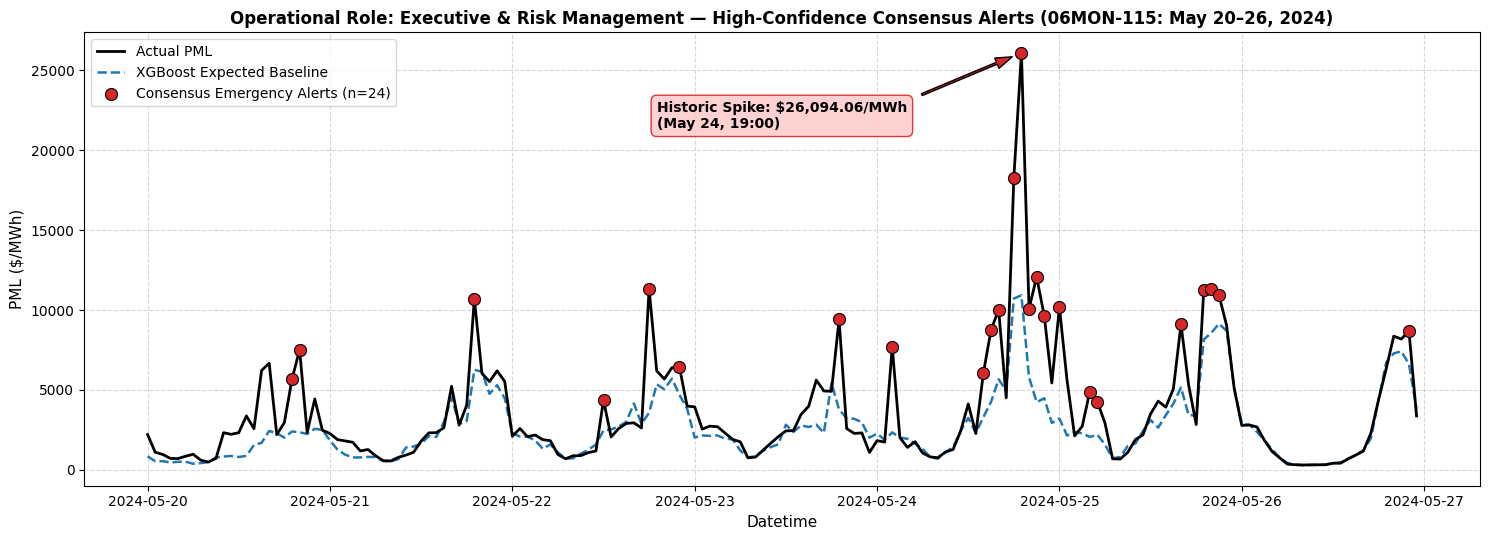

Executive Consensus Alerts Flagged: 24 hours out of 168 total hours (14.3%)


In [8]:
# High-Confidence Consensus Alerts
plt.figure(figsize=(15, 5.5))
plt.plot(crisis_df.index, crisis_df["pml"], color="black", linewidth=2.0, label="Actual PML", zorder=3)
plt.plot(crisis_df.index, crisis_df["pml_pred_xgb"], color="#1f77b4", linestyle="--", linewidth=1.8, label="XGBoost Expected Baseline", zorder=2)

crisis_cons = crisis_df[crisis_df["anom_consensus"]]
plt.scatter(
    crisis_cons.index,
    crisis_cons["pml"],
    color="#d62728",
    s=75,
    zorder=6,
    label=f"Consensus Emergency Alerts (n={len(crisis_cons)})",
    edgecolor="black",
    linewidth=0.8,
)

max_pt = crisis_df.loc[crisis_df["pml"].idxmax()]
plt.annotate(
    f"Historic Spike: ${max_pt['pml']:,.2f}/MWh\n(May 24, 19:00)",
    xy=(crisis_df["pml"].idxmax(), max_pt["pml"]),
    xytext=(crisis_df["pml"].idxmax() - pd.Timedelta(hours=48), max_pt["pml"] * 0.82),
    arrowprops=dict(facecolor="#d62728", shrink=0.08, width=1.5, headwidth=8),
    fontweight="bold",
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#ffcccc", edgecolor="#d62728", alpha=0.9),
)

plt.title(f"Operational Role: Executive & Risk Management — High-Confidence Consensus Alerts ({REF_NODE}: May 20–26, 2024)", fontsize=12, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper left", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Executive Consensus Alerts Flagged: {len(crisis_cons)} hours out of 168 total hours ({len(crisis_cons)/168*100:.1f}%)")

## Key Findings & Slide Deck Takeaways (Track A Bonus)

1. **Complementary Detection Synergy & Role Specialization:**
   - **XGBoost Residuals (Role: Trading/Commercial Dispatch):** Effectively flags temporal and contextual outliers (unforeseen evening surges and diurnal deviations) in blue.
   - **Isolation Forest (Role: Grid Reliability/Substations):** Isolates multi-component physical distortion (`pml_cng` congestion crises and transmission bottlenecks) in orange.
   - The **Consensus Detector (Role: Executive/Risk Management):** Yields a high-confidence alert layer with an inter-method Jaccard agreement of **0.421**, reducing noise to a disciplined ~0.9% alert rate in red.

2. **Extreme Spike Detection Performance:**
   - **Isolation Forest** flags **100.0%** of catastrophic shocks (>10,000 MXN/MWh, representing the 99.66th empirical percentile / 0.34% tail risk), capturing all 402 extreme shock hours.
   - **XGBoost Residuals** and the **Consensus Detector** capture **92.0%** of extreme spikes. The remaining 8% occur during prolonged multi-day crisis episodes where 24-hour autoregressive features (`pml_lag_24`, rolling averages) partially elevate the expected baseline, narrowing the residual below the P98.5 threshold.
   - Both methods successfully flag the system-wide historic record shock of **26,094.06 MXN/MWh on reference node 06MON-115 (reaching 26,222.27 MXN/MWh on 06AEO-115)** on May 24, 2024 at 19:00.

3. **Operational Value for Analyst Workflows:**
   - In trading and industrial dispatch operations, filtering hours by `anom_consensus == True` provides an automated early-warning system that catches transmission contingency shocks without drowning traders in false alarms (maintaining a disciplined ~0.9% consensus alert rate).